# Early Disease Prediction — Exploratory Data Analysis

HCLTech Career Shaper Programme | Project 29

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('../data/dataset.csv')
print('Dataset shape:', df.shape)
df.head()

Dataset shape: (5000, 8)


,patient_id,age,bmi,blood_pressure,glucose,cholesterol,smoking,label
0,P0001,30,20.7,136,156,191,1,1
1,P0002,67,27.7,128,87,158,0,1
2,P0003,73,18.7,106,131,273,0,0
3,P0004,43,21.7,120,172,161,0,0
4,P0005,50,37.5,95,140,206,0,0


In [6]:
# 1. Dataset quality checks

print("Dataset shape:", df.shape)

print("\nColumn data types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("Duplicate patient IDs:", df["patient_id"].duplicated().sum())

print("\nLabel distribution:")
print(df["label"].value_counts().sort_index())

print("\nSmoking values:")
print(sorted(df["smoking"].dropna().unique()))

print("\nNumerical summary:")
display(df.describe().round(2))

Dataset shape: (5000, 8)

Column data types:
patient_id            str
age                 int64
bmi               float64
blood_pressure      int64
glucose             int64
cholesterol         int64
smoking             int64
label               int64
dtype: object

Missing values:
patient_id        0
age               0
bmi               0
blood_pressure    0
glucose           0
cholesterol       0
smoking           0
label             0
dtype: int64

Duplicate rows: 0
Duplicate patient IDs: 0

Label distribution:
label
0    2553
1    2447
Name: count, dtype: int64

Smoking values:
[np.int64(0), np.int64(1)]

Numerical summary:


,age,bmi,blood_pressure,glucose,cholesterol,smoking,label
count,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00
mean,47.19,28.07,121.45,125.79,219.01,0.32,0.49
std,14.38,5.89,19.80,35.34,42.23,0.46,0.50
min,21.00,15.00,60.00,50.00,100.00,0.00,0.00
25%,37.00,23.90,109.00,100.00,190.00,0.00,0.00
50%,47.00,28.00,122.00,125.00,218.00,0.00,0.00
75%,57.00,32.20,135.00,150.00,248.00,1.00,1.00
max,90.00,46.50,187.00,256.00,364.00,1.00,1.00


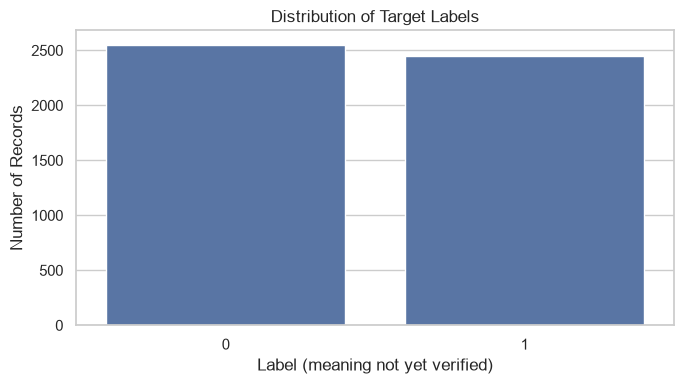

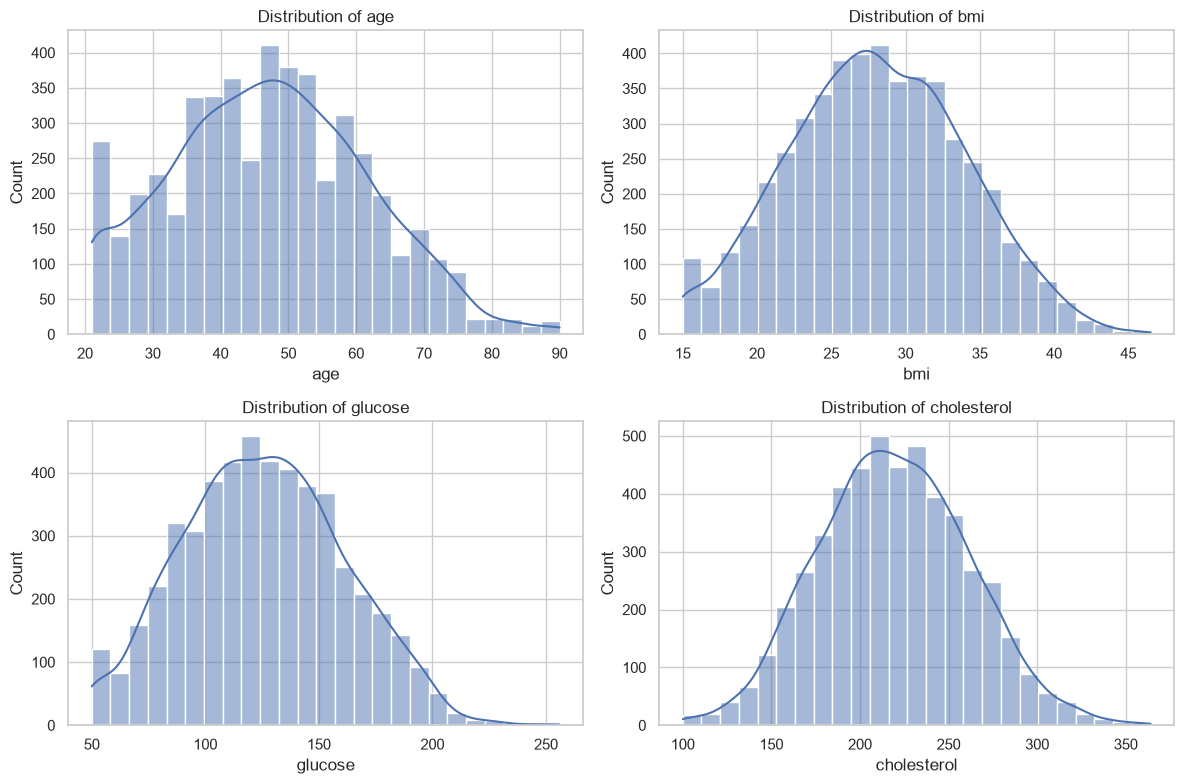

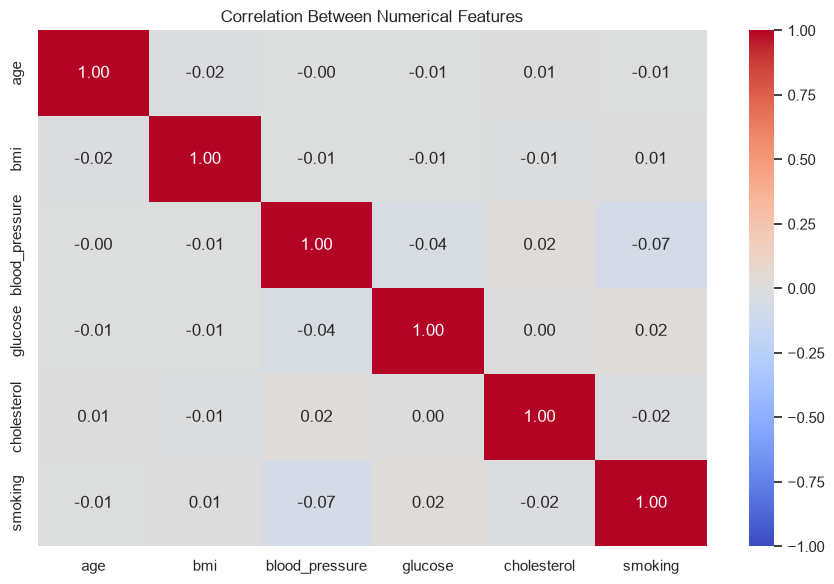

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Chart 1: Label distribution
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="label")
plt.title("Distribution of Target Labels")
plt.xlabel("Label (meaning not yet verified)")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

# Chart 2: Health feature distributions
features = ["age", "bmi", "glucose", "cholesterol"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for feature, ax in zip(features, axes.flatten()):
    sns.histplot(data=df, x=feature, bins=25, kde=True, ax=ax)
    ax.set_title(f"Distribution of {feature}")

plt.tight_layout()
plt.show()

# Chart 3: Correlation heatmap
numeric_df = df.select_dtypes(include="number").drop(
    columns=["label"], errors="ignore"
)

plt.figure(figsize=(9, 6))
sns.heatmap(
    numeric_df.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)
plt.title("Correlation Between Numerical Features")
plt.tight_layout()
plt.show()

In [8]:
# Create the project data dictionary

import pandas as pd

dictionary = pd.DataFrame([
    {
        "column": "patient_id",
        "data_type": "string",
        "description": "Unique identifier assigned to each record",
        "role": "Identifier",
        "notes": "Exclude from model training"
    },
    {
        "column": "age",
        "data_type": "integer",
        "description": "Age of the individual in years",
        "role": "Feature",
        "notes": "Validate permitted range"
    },
    {
        "column": "bmi",
        "data_type": "float",
        "description": "Body mass index",
        "role": "Feature",
        "notes": "Confirm units and data provenance"
    },
    {
        "column": "blood_pressure",
        "data_type": "integer",
        "description": "Blood pressure measurement",
        "role": "Feature",
        "notes": "Measurement type and units need confirmation"
    },
    {
        "column": "glucose",
        "data_type": "float",
        "description": "Blood glucose measurement",
        "role": "Feature",
        "notes": "Confirm measurement units"
    },
    {
        "column": "cholesterol",
        "data_type": "integer",
        "description": "Cholesterol measurement",
        "role": "Feature",
        "notes": "Confirm measurement units"
    },
    {
        "column": "smoking",
        "data_type": "integer",
        "description": "Smoking-status indicator",
        "role": "Feature",
        "notes": "Observed values: 0 and 1; confirm encoding"
    },
    {
        "column": "label",
        "data_type": "integer",
        "description": "Binary target value",
        "role": "Target",
        "notes": "Medical meaning of 0 and 1 is not yet verified"
    }
])

dictionary.to_csv("../data/data_dictionary.csv", index=False)

print("Data dictionary created successfully!")
display(dictionary)

Data dictionary created successfully!


,column,data_type,description,role,notes
0,patient_id,string,Unique identifier assigned to each record,Identifier,Exclude from model training
1,age,integer,Age of the individual in years,Feature,Validate permitted range
2,bmi,float,Body mass index,Feature,Confirm units and data provenance
3,blood_pressure,integer,Blood pressure measurement,Feature,Measurement type and units need confirmation
4,glucose,float,Blood glucose measurement,Feature,Confirm measurement units
5,cholesterol,integer,Cholesterol measurement,Feature,Confirm measurement units
6,smoking,integer,Smoking-status indicator,Feature,Observed values: 0 and 1; confirm encoding
7,label,integer,Binary target value,Target,Medical meaning of 0 and 1 is not yet verified



## Exploratory Data Analysis — Key Findings

### 1. Dataset Overview

The dataset contains 5,000 records and eight columns, including six input features, one patient identifier and one binary target label.

The dataset was checked for missing values, duplicate records and duplicate patient identifiers. No missing cells or duplicate records were detected.

### 2. Target Variable Distribution

The target variable contains two classes:

- Label 0: 2,553 records (51.06%).
- Label 1: 2,447 records (48.94%).

The two classes are relatively balanced. However, the clinical meaning of these labels has not been independently verified.

### 3. Feature Distribution

The average age is 47.19 years, while the average BMI is 28.07.

The mean glucose measurement is 125.79, average blood pressure is 121.45, and average cholesterol measurement is 219.01.

Histograms were used to examine the distribution and spread of these numerical features.

### 4. Correlation Analysis

A correlation heatmap was generated to explore relationships between numerical variables.

Correlation indicates statistical association, not causation. The observed relationships should not be interpreted as evidence of medical risk or disease causation.

### 5. Data Quality Observations

The dataset contains no missing cells, duplicate records or duplicate patient identifiers.

The smoking and target columns use binary encodings.

### 6. Limitations

The dataset includes synthetically generated records. The provenance and clinical meaning of the target variable have not been independently validated.

Therefore, the EDA findings and subsequent model results are intended for educational experimentation, not clinical decision-making.
